In [30]:
import numpy as np
import pandas as pd

import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer


Log Transform
- It is used on right skewed data ( makes it normally distributed, not exactly but better than before )

Reciprocal Transform
- small becomes large and large becomes small


Square Transform
- Usually used for left skewed data



Without Transform

In [2]:
# We are only using age, Fare and Survived columns

df = pd.read_csv("../datasets/titanic_dataset.csv",usecols=['Age','Fare','Survived'])
df.sample(4)

,Survived,Age,Fare
781,1,17.0,57.0000
704,0,26.0,7.8542
842,1,30.0,31.0000
615,1,24.0,65.0000


In [4]:
df['Age'].fillna(df['Age'].mean(), inplace=True)
df.sample(4)
df.isnull().sum()

C:\Users\Asim\AppData\Local\Temp\ipykernel_87744\1967790319.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)


Survived    0
Age         0
Fare        0
dtype: int64

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    df.iloc[:,1:3], # 1 ra 2 index herxa
    df.iloc[:,0],
    test_size=0.2,
    random_state=42
)

In [8]:
X_train

,Age,Fare
331,45.500000,28.5000
733,23.000000,13.0000
382,32.000000,7.9250
704,26.000000,7.8542
813,6.000000,31.2750
...,...,...
106,21.000000,7.6500
270,29.699118,31.0000
860,41.000000,14.1083
435,14.000000,120.0000


QQ Plot

<Axes: xlabel='Age', ylabel='Density'>

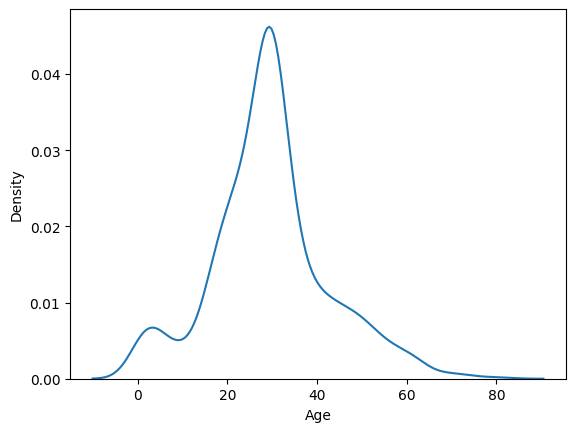

In [12]:
sns.kdeplot(X_train['Age'])

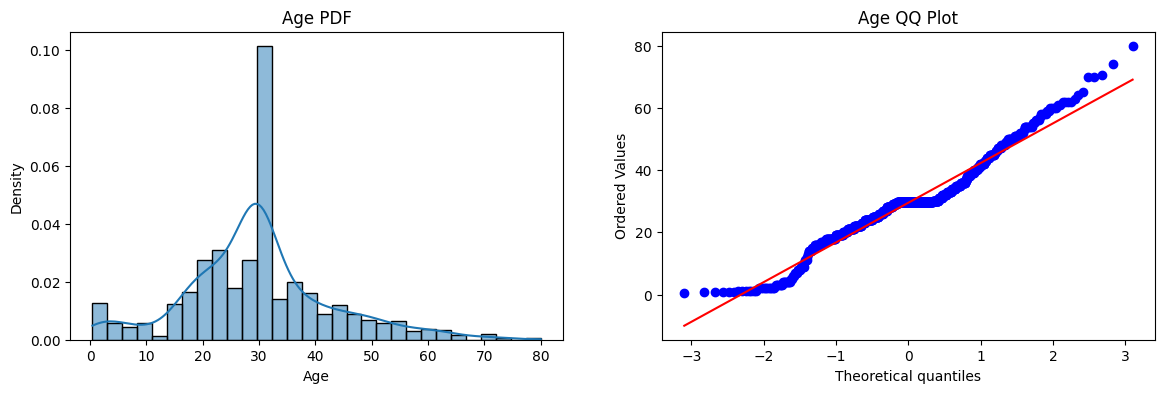

In [20]:
plt.figure(figsize = (14,4))

plt.subplot(121)
sns.histplot(x='Age', data=df, kde=True, stat='density')
plt.title("Age PDF")

plt.subplot(122)
stats.probplot(X_train['Age'], dist='norm', plot = plt)
plt.title("Age QQ Plot")

plt.show()


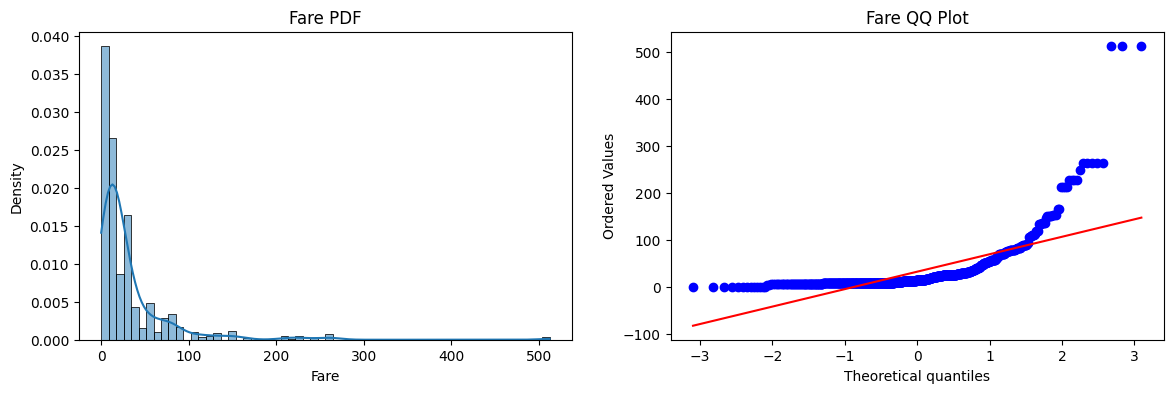

In [21]:
plt.figure(figsize = (14,4))

plt.subplot(121)
sns.histplot(x='Fare', data=df, kde=True, stat='density')
plt.title("Fare PDF")

plt.subplot(122)
stats.probplot(X_train['Fare'], dist='norm', plot = plt)
plt.title("Fare QQ Plot")

plt.show()

In [32]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [33]:
clf.fit(X_train, y_train)
clf2.fit(X_train,y_train)

y_pred = clf.predict(X_test)
y_pred2 = clf2.predict(X_test)

print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred2))

Accuracy LR 0.6480446927374302
Accuracy DT 0.664804469273743


In [34]:
trf = FunctionTransformer(func = np.log1p)
#log1p le chai 1 add gardinxa, to avoid log0

In [35]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [36]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed, y_train)
clf2.fit(X_train_transformed,y_train)

y_pred = clf.predict(X_test_transformed)
y_pred2 = clf2.predict(X_test_transformed)

print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred2))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6927374301675978


In [38]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]
X_transformed = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR", np.mean(cross_val_score(clf, X_transformed, y, scoring = 'accuracy', cv = 10)))
print("DT", np.mean(cross_val_score(clf2, X_transformed, y, scoring = 'accuracy', cv = 10)))

LR 0.678027465667915
DT 0.6577528089887641


QQ plot of fare before and after log transform

Text(0.5, 1.0, 'Fare after Log Transform')

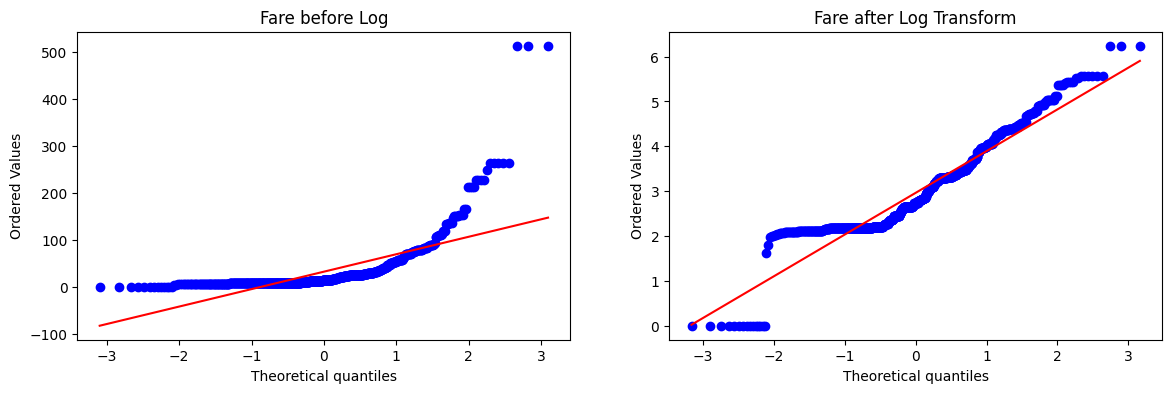

In [40]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist='norm', plot = plt)
plt.title('Fare before Log')

plt.subplot(122)
stats.probplot(X_transformed['Fare'], dist='norm', plot =plt)
plt.title("Fare after Log Transform")

Text(0.5, 1.0, 'Age after Log Transform')

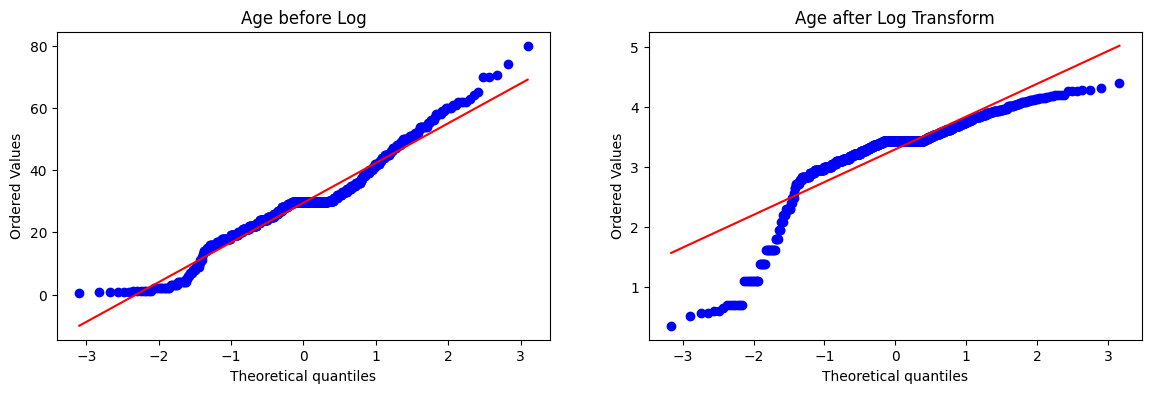

In [41]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'], dist='norm', plot = plt)
plt.title('Age before Log')

plt.subplot(122)
stats.probplot(X_transformed['Age'], dist='norm', plot =plt)
plt.title("Age after Log Transform")

Ahile samma k vayo vanda, yes Fare ko normal distribution ko najeek aayo, but age chai jhan naramro vayo, yo esai pani right skewed thiyena, so now we are going to transform just the Fare column

In [44]:
trf2 = ColumnTransformer([
    ('log', FunctionTransformer(np.log1p), ['Fare'])
    ], remainder='passthrough')

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)


In [64]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier(random_state=42)

clf.fit(X_train_transformed2, y_train)
clf2.fit(X_train_transformed2,y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)

print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred2))

Accuracy LR 0.6703910614525139
Accuracy DT 0.659217877094972
